# HiggsML Classifier – CERN Open Data Project

This notebook implements a binary classification model to separate signal and background events using the Higgs Boson Challenge dataset.

Author: Ahmet Can Çömez

## Importing Dependencies

This cell loads all required libraries for data handling, preprocessing, model training, evaluation, and persistence:

- `pandas`: for data manipulation and numerical operations
- `matplotlib.pyplot`, `seaborn`: for plotting and visualization
- `scikit-learn`: for preprocessing, model building, and evaluation
- `joblib`: to save the trained model
- `os`: for handling file paths



In [1]:
import pandas as pd
import numpy as np
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

## Loading the Dataset

The dataset is loaded from a local CSV file.
We first inspect the shape of the data to understand the number of samples and features, and then display the first few rows using `head()` to preview the structure.


In [2]:
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
training_path = os.path.join(project_root, "data", "training.csv")
df = pd.read_csv(training_path)
df.head()


,EventId,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,DER_pt_h,DER_deltaeta_jet_jet,DER_mass_jet_jet,DER_prodeta_jet_jet,DER_deltar_tau_lep,DER_pt_tot,...,PRI_jet_num,PRI_jet_leading_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_subleading_pt,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_all_pt,Weight,Label
0,100000,138.470,51.655,97.827,27.980,0.91,124.711,2.666,3.064,41.928,...,2,67.435,2.150,0.444,46.062,1.24,-2.475,113.497,0.002653,s
1,100001,160.937,68.768,103.235,48.146,-999.00,-999.000,-999.000,3.473,2.078,...,1,46.226,0.725,1.158,-999.000,-999.00,-999.000,46.226,2.233584,b
2,100002,-999.000,162.172,125.953,35.635,-999.00,-999.000,-999.000,3.148,9.336,...,1,44.251,2.053,-2.028,-999.000,-999.00,-999.000,44.251,2.347389,b
3,100003,143.905,81.417,80.943,0.414,-999.00,-999.000,-999.000,3.310,0.414,...,0,-999.000,-999.000,-999.000,-999.000,-999.00,-999.000,-0.000,5.446378,b
4,100004,175.864,16.915,134.805,16.405,-999.00,-999.000,-999.000,3.891,16.405,...,0,-999.000,-999.000,-999.000,-999.000,-999.00,-999.000,0.000,6.245333,b


In [3]:


# Raw counts
print("Class counts:")
print(df['Label'].value_counts())

# Percentages
print("\nClass percentages:")
print(df['Label'].value_counts(normalize=True) * 100)



Class counts:
Label
b    164333
s     85667
Name: count, dtype: int64

Class percentages:
Label
b    65.7332
s    34.2668
Name: proportion, dtype: float64


In [4]:
x=df.isnull().sum()
y=(df.isnull().sum()/df.shape[0])*100
z={'Number of missing values':x,'Percentage of missing values':y}
dataset=pd.DataFrame(z,columns=['Number of missing values','Percentage of missing values'])
dataset.sort_values(by='Percentage of missing values',ascending =False)


,Number of missing values,Percentage of missing values
EventId,0,0.0
PRI_lep_pt,0,0.0
Weight,0,0.0
PRI_jet_all_pt,0,0.0
PRI_jet_subleading_phi,0,0.0
PRI_jet_subleading_eta,0,0.0
PRI_jet_subleading_pt,0,0.0
PRI_jet_leading_phi,0,0.0
PRI_jet_leading_eta,0,0.0
PRI_jet_leading_pt,0,0.0


In [5]:
df.drop_duplicates(inplace=True)

In [6]:
df.columns

Index(['EventId', 'DER_mass_MMC', 'DER_mass_transverse_met_lep',
       'DER_mass_vis', 'DER_pt_h', 'DER_deltaeta_jet_jet', 'DER_mass_jet_jet',
       'DER_prodeta_jet_jet', 'DER_deltar_tau_lep', 'DER_pt_tot', 'DER_sum_pt',
       'DER_pt_ratio_lep_tau', 'DER_met_phi_centrality',
       'DER_lep_eta_centrality', 'PRI_tau_pt', 'PRI_tau_eta', 'PRI_tau_phi',
       'PRI_lep_pt', 'PRI_lep_eta', 'PRI_lep_phi', 'PRI_met', 'PRI_met_phi',
       'PRI_met_sumet', 'PRI_jet_num', 'PRI_jet_leading_pt',
       'PRI_jet_leading_eta', 'PRI_jet_leading_phi', 'PRI_jet_subleading_pt',
       'PRI_jet_subleading_eta', 'PRI_jet_subleading_phi', 'PRI_jet_all_pt',
       'Weight', 'Label'],
      dtype='str')

<Axes: >

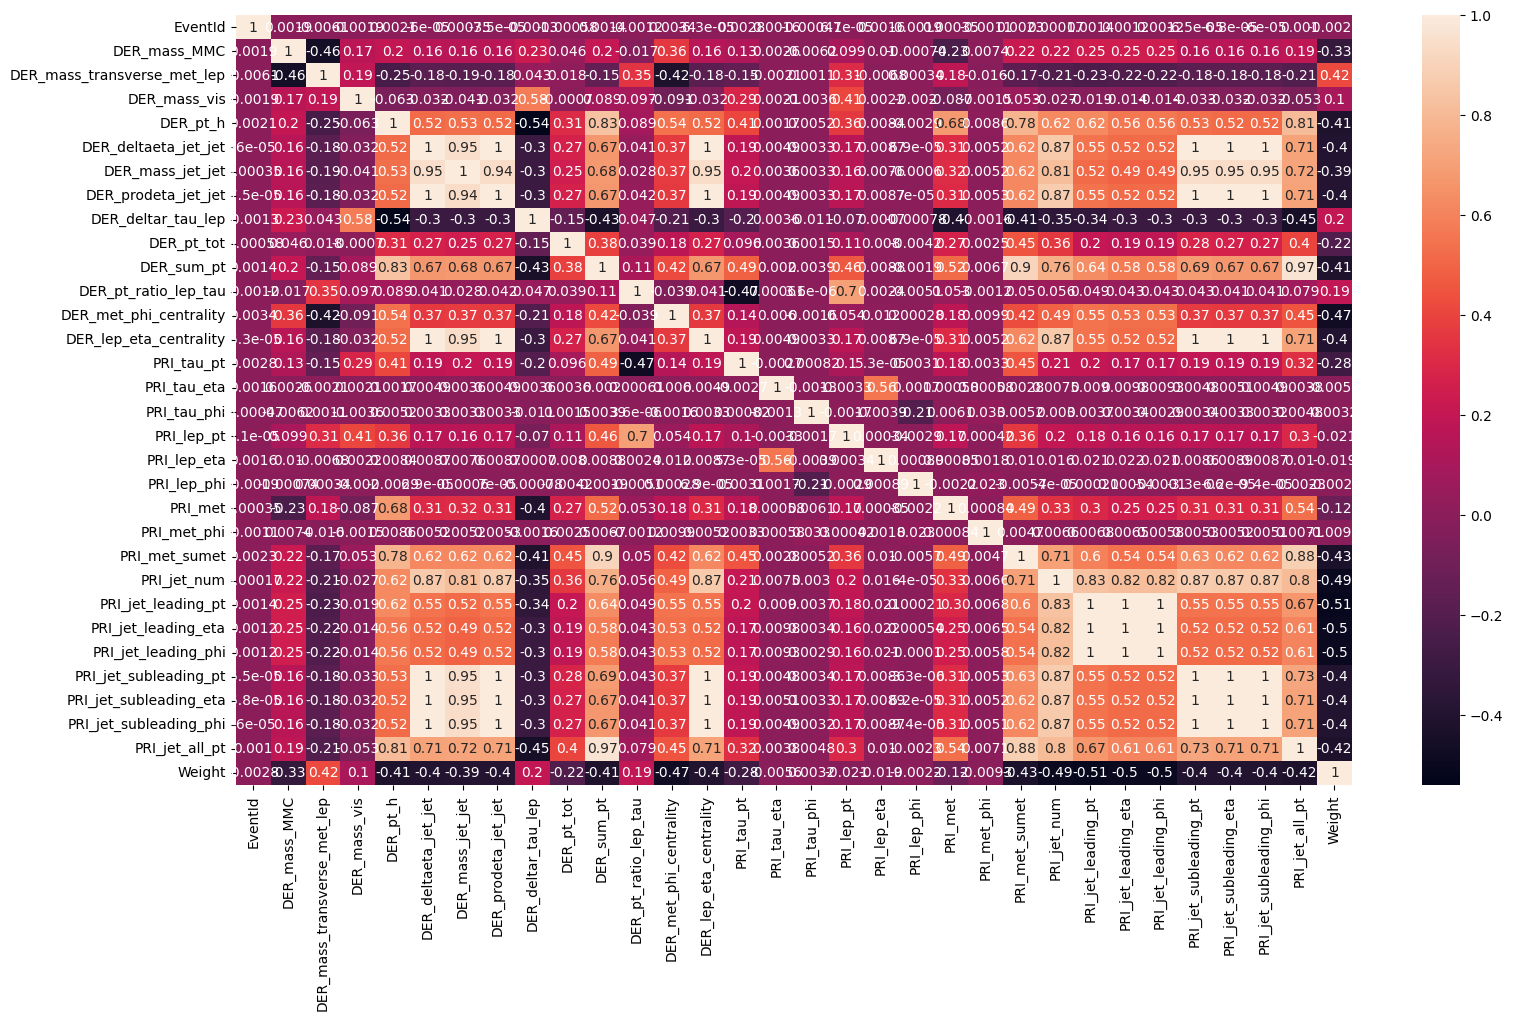

In [7]:
plt.rcParams['figure.figsize']=(18,10)
sns.heatmap(df[['EventId', 'DER_mass_MMC', 'DER_mass_transverse_met_lep',
       'DER_mass_vis', 'DER_pt_h', 'DER_deltaeta_jet_jet', 'DER_mass_jet_jet',
       'DER_prodeta_jet_jet', 'DER_deltar_tau_lep', 'DER_pt_tot', 'DER_sum_pt',
       'DER_pt_ratio_lep_tau', 'DER_met_phi_centrality',
       'DER_lep_eta_centrality', 'PRI_tau_pt', 'PRI_tau_eta', 'PRI_tau_phi',
       'PRI_lep_pt', 'PRI_lep_eta', 'PRI_lep_phi', 'PRI_met', 'PRI_met_phi',
       'PRI_met_sumet', 'PRI_jet_num', 'PRI_jet_leading_pt',
       'PRI_jet_leading_eta', 'PRI_jet_leading_phi', 'PRI_jet_subleading_pt',
       'PRI_jet_subleading_eta', 'PRI_jet_subleading_phi', 'PRI_jet_all_pt',
       'Weight' ]].corr(),annot=True)

In [8]:



corr = df.drop(columns=["Label"]).corr().abs()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = [
    (column, row, upper.loc[row, column])
    for column in upper.columns
    for row in upper.index
    if upper.loc[row, column] > 0.90
]

for col1, col2, value in high_corr:
    print(f"{col1} <-> {col2}: {value:.2f}")
    
    
 

DER_mass_jet_jet <-> DER_deltaeta_jet_jet: 0.95
DER_prodeta_jet_jet <-> DER_deltaeta_jet_jet: 1.00
DER_prodeta_jet_jet <-> DER_mass_jet_jet: 0.94
DER_lep_eta_centrality <-> DER_deltaeta_jet_jet: 1.00
DER_lep_eta_centrality <-> DER_mass_jet_jet: 0.95
DER_lep_eta_centrality <-> DER_prodeta_jet_jet: 1.00
PRI_met_sumet <-> DER_sum_pt: 0.90
PRI_jet_leading_eta <-> PRI_jet_leading_pt: 1.00
PRI_jet_leading_phi <-> PRI_jet_leading_pt: 1.00
PRI_jet_leading_phi <-> PRI_jet_leading_eta: 1.00
PRI_jet_subleading_pt <-> DER_deltaeta_jet_jet: 1.00
PRI_jet_subleading_pt <-> DER_mass_jet_jet: 0.95
PRI_jet_subleading_pt <-> DER_prodeta_jet_jet: 1.00
PRI_jet_subleading_pt <-> DER_lep_eta_centrality: 1.00
PRI_jet_subleading_eta <-> DER_deltaeta_jet_jet: 1.00
PRI_jet_subleading_eta <-> DER_mass_jet_jet: 0.95
PRI_jet_subleading_eta <-> DER_prodeta_jet_jet: 1.00
PRI_jet_subleading_eta <-> DER_lep_eta_centrality: 1.00
PRI_jet_subleading_eta <-> PRI_jet_subleading_pt: 1.00
PRI_jet_subleading_phi <-> DER_deltae

In [9]:
columns=df.columns

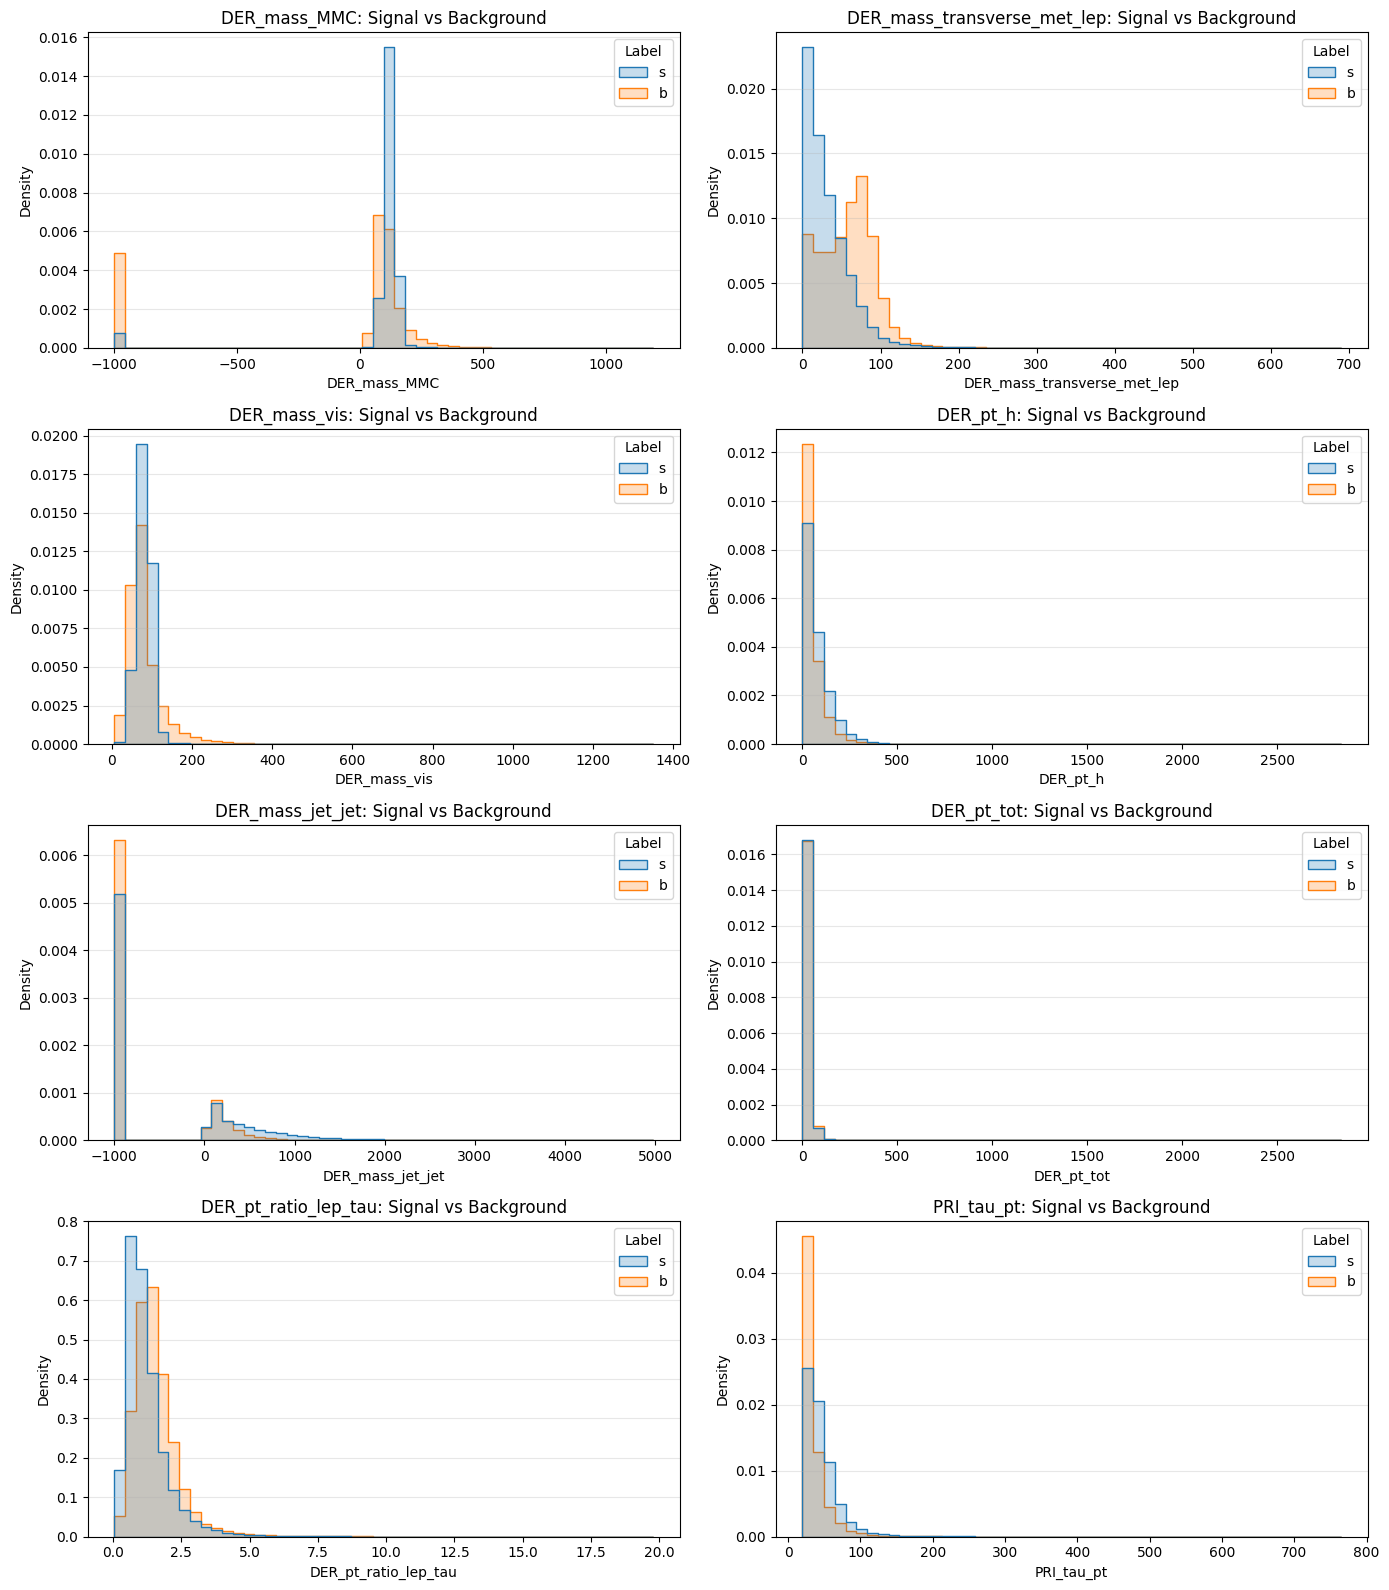

In [10]:



features_to_plot = [
    "DER_mass_MMC",
    "DER_mass_transverse_met_lep",
    "DER_mass_vis",
    "DER_pt_h",
    "DER_mass_jet_jet",
    "DER_pt_tot",
    "DER_pt_ratio_lep_tau",
    "PRI_tau_pt"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, col in zip(axes.flatten(), features_to_plot):
    sns.histplot(
        data=df,
        x=col,
        hue="Label",
        bins=50,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax
    )
    ax.set_title(f"{col}: Signal vs Background")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Special `-999` Values

Some features contain a value of `-999`, which does not represent a physically meaningful measurement. It is used in the dataset to indicate that a particular quantity was unavailable or could not be reconstructed for an event.

Therefore, `-999` values should not be interpreted as actual minimum physical values. They are retained during preprocessing so that the model can learn whether the presence of an unavailable measurement carries useful information.

## Target Variable Encoding

The categorical target column `Label` is converted to binary numerical values:
- `'s'` (signal) → 1
- `'b'` (background) → 0

This transformation is required for compatibility with machine learning algorithms.
The updated distribution is reviewed to verify label encoding and assess class balance.


In [11]:
df['Label'] = df['Label'].map({'s': 1, 'b': 0})

## Dataset Overview

A concise summary of the dataset is obtained using `df.info()`.
This includes column data types, non-null counts, and memory usage.
The output is useful for detecting missing values and verifying dataset structure prior to preprocessing.


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   EventId                      250000 non-null  int64  
 1   DER_mass_MMC                 250000 non-null  float64
 2   DER_mass_transverse_met_lep  250000 non-null  float64
 3   DER_mass_vis                 250000 non-null  float64
 4   DER_pt_h                     250000 non-null  float64
 5   DER_deltaeta_jet_jet         250000 non-null  float64
 6   DER_mass_jet_jet             250000 non-null  float64
 7   DER_prodeta_jet_jet          250000 non-null  float64
 8   DER_deltar_tau_lep           250000 non-null  float64
 9   DER_pt_tot                   250000 non-null  float64
 10  DER_sum_pt                   250000 non-null  float64
 11  DER_pt_ratio_lep_tau         250000 non-null  float64
 12  DER_met_phi_centrality       250000 non-null  float64
 13  DER_lep_et

## Visualizing Class Distribution

This count plot displays the distribution of the target classes:
Signal (`1`) and Background (`0`).
It helps identify any class imbalance that may affect model performance.


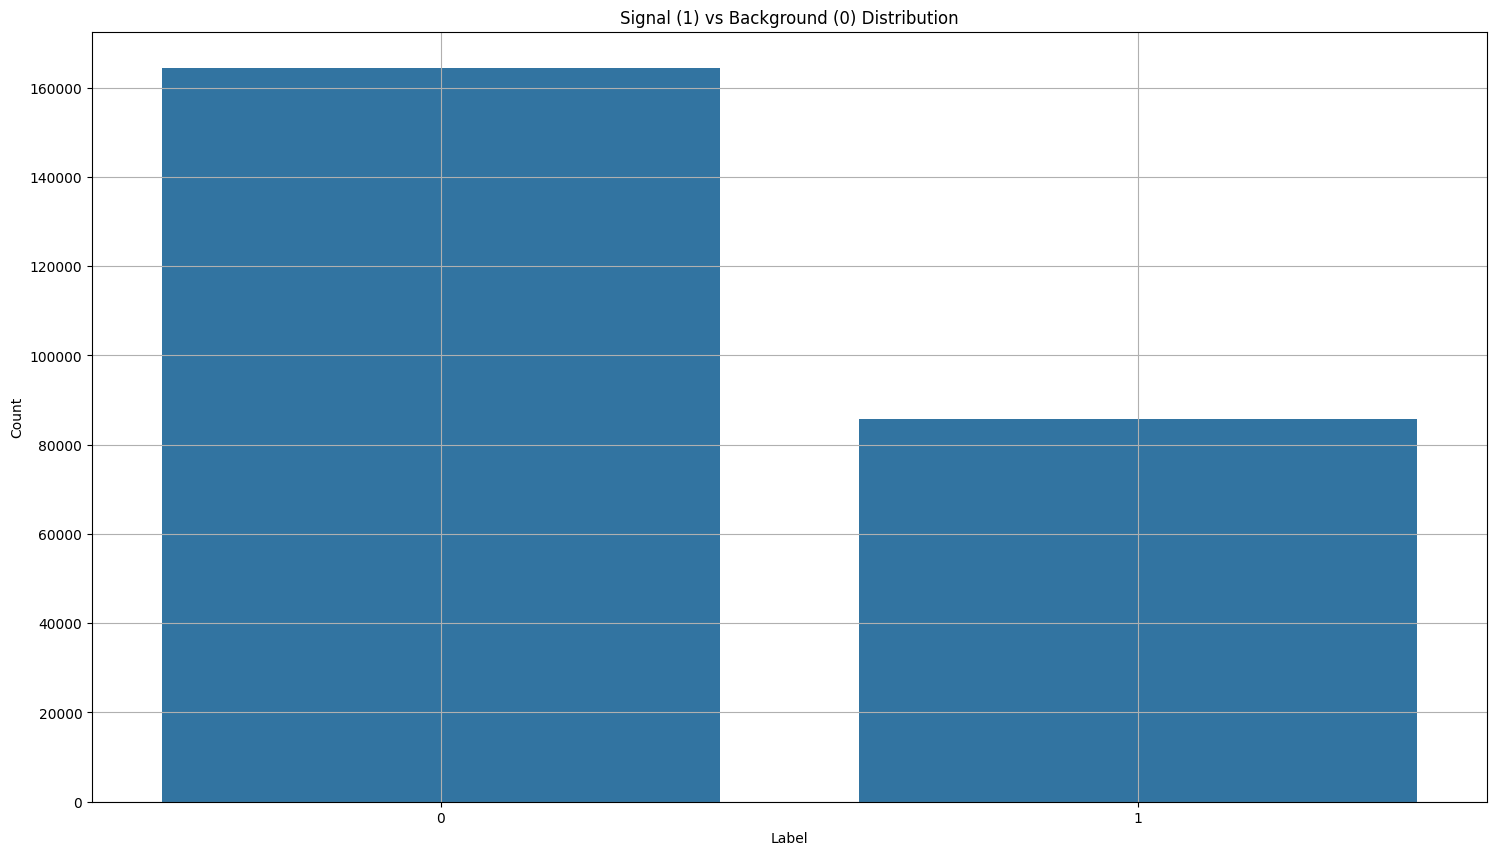

In [13]:
sns.countplot(x='Label', data=df)
plt.title("Signal (1) vs Background (0) Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.grid(True)
plt.show()

## Feature and Target Definition

The dataset is split into input features (`X`) and target labels (`Y`).
The `Label`, `Weight`, and `EventId` columns are excluded from the feature matrix as they are either target indicators or metadata.
This step structures the data appropriately for supervised learning.


In [14]:
X = df.drop(['Label', 'Weight', 'EventId'], axis=1)
Y = df['Label']

## Train-Test Split and Feature Scaling

The dataset is divided into training and testing subsets using an 80-20 split.
Feature standardization is then applied using `StandardScaler`, transforming the data to have zero mean and unit variance.
This preprocessing step is essential for optimizing the performance and stability of many machine learning algorithms, including gradient boosting.


In [15]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Gradient Boosting Classifier Training

A `GradientBoostingClassifier` is instantiated with the following hyperparameters:
- `learning_rate = 0.1`
- `max_depth = 5`
- `n_estimators = 200`
- `subsample = 0.8`

The model is fitted on the standardized training data.
After training, class predictions (`y_pred`) and predicted probabilities (`y_score`) are computed on the test set for subsequent evaluation.


In [ ]:
model = GradientBoostingClassifier(
    learning_rate=0.1,
    max_depth=5,
    n_estimators=200,
    subsample=0.8,
    random_state=42
)

model.fit(X_train_scaled, Y_train)
y_pred = model.predict(X_test_scaled)
y_score = model.predict_proba(X_test_scaled)[:, 1]




In [ ]:


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, Y_train)

rf_pred = rf_model.predict(X_test_scaled)

print(f"Random Forest Accuracy: {accuracy_score(Y_test, rf_pred):.4f}")
print("\nClassification Report:")
print(classification_report(
    Y_test,
    rf_pred,
    target_names=["Background", "Signal"]
))

    

## ROC Curve and AUC Score Evaluation

The Receiver Operating Characteristic (ROC) curve is generated to assess the model's classification performance.
The Area Under the Curve (AUC) is calculated to quantify the classifier's ability to distinguish between signal and background classes.
AUC values closer to 1.0 indicate strong predictive performance.


In [ ]:
fpr, tpr, thresholds = roc_curve(Y_test, y_score)
auc_score = roc_auc_score(Y_test, y_score)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

## Confusion Matrix and Accuracy Score

The confusion matrix is computed to provide a detailed breakdown of prediction results, showing true positives, false positives, true negatives, and false negatives.
The accuracy score is also calculated to measure the overall proportion of correctly classified samples.
This evaluation helps in understanding the model’s performance beyond a single metric.


In [ ]:
cm = confusion_matrix(Y_test, rf_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Background (0)", "Signal (1)"])
disp.plot(cmap='Blues')

acc = accuracy_score(Y_test, rf_pred)
print(f"Accuracy: {acc:.4f}")

## Saving the Trained Model

The trained `GradientBoostingClassifier` is serialized and saved using the `joblib` library.
This allows the model to be reloaded later for inference or integration into other systems without retraining.


In [ ]:
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
model_path = os.path.join(project_root, "models", "higgs_classifier.joblib")
print(f"Saving model to {model_path}")
joblib.dump(model, model_path)

## Conclusion

This project used machine learning to classify Higgs boson collision events as signal or background. Exploratory data analysis was used to examine the class distribution, feature distributions, correlation

After preprocessing and removing redundant features, a Gradient Boosting classifier was trained and evaluated using accuracy, precision, recall, F1-score, a confusion matrix, and ROC-AUC.

The results demonstrate that machine learning can effectively distinguish signal-like events from background events in high-energy physics data. The analysis also highlights the importance of understanding the physical meaning and quality of the input features before training a model.